# B 날씨 사건 · 연구 기간 · 악천후일 목록

담당: B · 결과물은 **Train + Dev(`train_dev`) / Test(`holdout`)** 로 나눠 저장한다. Train과 Dev는 `model_set` 열로 고른다.

1. ASOS 받기: 터미널에서 `python crawling/kma_asos.py` (api_keys.txt 에 `DATA_GO_KR_KEY=` 필요)
   - API가 안 되면 기상자료개방포털에서 받은 CSV를 `data/raw/asos_manual/` 에 넣어도 된다.
2. 기상특보 받기: `python crawling/kma_warning.py` (크롬이 열려 자동으로 조회 · 페이지 넘김 · 상세 수집)
3. 표 만들기: 터미널에서 `python src/clean/weather.py`. 이 노트북은 같은 계산을 단계별로 보여 준다. 마지막 저장 셀은 처음 셀의 `RUN_BUILD = True`일 때만 저장한다 (기본 `False`라 다시 실행해도 공통 표를 덮어쓰지 않는다).

| 결과 | 위치 |
|---|---|
| 시간별 날씨 | `data/shared/train_dev/weather_hourly_train_dev.csv`, `data/shared/holdout/weather_hourly_holdout.csv` |
| 눈 · 비 사건 | `data/shared/{train_dev,holdout}/weather_events_*.csv` |
| 악천후일 · 비교일 (C 교통량 수집용) | `data/shared/{train_dev,holdout}/weather_days_*.csv` |
| 시즌별 첫 · 마지막 날, 연구 기간 후보 | `outputs/tables/season_first_last.csv`, `outputs/tables/research_period_options.csv` |
| 서울 특보 구간 (생존분석 출발점) | `data/shared/{train_dev,holdout}/weather_warnings_*.csv` |
| 연구 기간 · 기준값 (팀 공유) | `config/periods.yaml` |

In [1]:
import sys
from pathlib import Path
def find_project_root(start=None):
    """지금 폴더에서 위로 올라가며 README.md와 .git이 있는 저장소 루트를 찾는다."""
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').is_file() and (candidate / '.git').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트를 찾지 못했습니다.')

ROOT = find_project_root()
RUN_BUILD = False  # True로 바꿀 때만 마지막 셀에서 공통 표 · periods.yaml을 저장한다 (기본은 계산 · 그림만)
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src.clean import weather as W

plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 한글 글꼴
plt.rcParams['axes.unicode_minus'] = False
W.THRESHOLDS

{'snow_temp_c': 1.0,
 'event_gap_h': 3,
 'snow_light_cm': 1.0,
 'snow_heavy_cm': 5.0,
 'rain_strong_mmh': 5.0,
 'rain_heavy_mmh': 30.0,
 'rain_heavy_total_mm': 80.0,
 'summer_day_mm': 30.0,
 'congestion_link_ratio': 1.5,
 'congestion_road_length_ratio': 0.3,
 'freezing_temp_c': 0.5,
 'impact_after_snow_h': 12,
 'impact_after_rain_h': 3}

## 1. 읽기 · 시즌 구분

In [2]:
raw = W.add_season(W.load_asos())
print(raw['datetime'].min(), '~', raw['datetime'].max(), len(raw), '시간')
print('관측 빠진 시간:', int(raw['missing_obs'].sum()))
raw.groupby(['split', 'season']).size()

2022-10-01 00:00:00 ~ 2026-09-30 23:00:00 35064 시간
관측 빠진 시간: 0


split  season
eval   S2026     3672
       W2025     5088
train  S2023     3672
       S2024     3672
       S2025     3672
       W2022     5088
       W2023     5112
       W2024     5088
dtype: int64

## 2. 눈 · 비 사건

In [3]:
hourly, ev = W.extract_events(raw)
ev.groupby(['split', 'season', 'intensity']).size().unstack(fill_value=0)

intensity     강한 비  눈(안 쌓임)  많은 눈  보통 눈  약한 눈  약한 비  호우
split season                                           
eval  S2026     13        0     0     0     0    52   2
      W2025      8        5     2     4     1    44   0
train S2023     18        0     0     0     0    41   4
      S2024     19        0     0     0     0    47   2
      S2025     19        0     0     0     0    41   3
      W2022      4       13     0     5     5    37   1
      W2023      7       12     3     9     1    39   0
      W2024      2       19     4     6     4    43   0

## 3. 시즌별 첫 · 마지막 날

겨울은 **쌓인 눈(신적설 0.1cm 이상)** 기준, 여름은 **하루 30mm 이상 큰비 날** 기준이다. 안 쌓인 눈까지 포함한 첫 · 마지막 눈도 참고로 적었다.

In [4]:
fl = W.first_last(hourly, ev)
fl[['name', 'split', 'kind', 'first', 'last', 'n_events', 'first_any_snow', 'last_any_snow']]

,name,split,kind,first,last,n_events,first_any_snow,last_any_snow
0,2022~23 겨울,train,겨울 (쌓인 눈),2022-12-03 03:00:00,2023-01-26 15:00:00,10,2022-11-29 23:00:00,2023-02-16 13:00:00
1,2023~24 겨울,train,겨울 (쌓인 눈),2023-12-14 09:00:00,2024-02-25 09:00:00,13,2023-11-17 12:00:00,2024-03-07 06:00:00
2,2024~25 겨울,train,겨울 (쌓인 눈),2024-11-26 00:00:00,2025-04-13 03:00:00,14,2024-11-26 00:00:00,2025-04-13 03:00:00
3,2023 여름,train,여름 (하루 30mm 이상),2023-05-06 00:00:00,2023-09-20 00:00:00,20,NaT,NaT
4,2024 여름,train,여름 (하루 30mm 이상),2024-05-05 00:00:00,2024-09-21 00:00:00,14,NaT,NaT
5,2025 여름,train,여름 (하루 30mm 이상),2025-05-16 00:00:00,2025-09-28 00:00:00,14,NaT,NaT
6,2025~26 겨울,eval,겨울 (쌓인 눈),2025-12-04 18:00:00,2026-03-06 01:00:00,7,2025-12-04 18:00:00,2026-03-06 13:00:00
7,2026 여름,eval,여름 (하루 30mm 이상),2026-05-20 00:00:00,2026-08-31 00:00:00,9,NaT,NaT


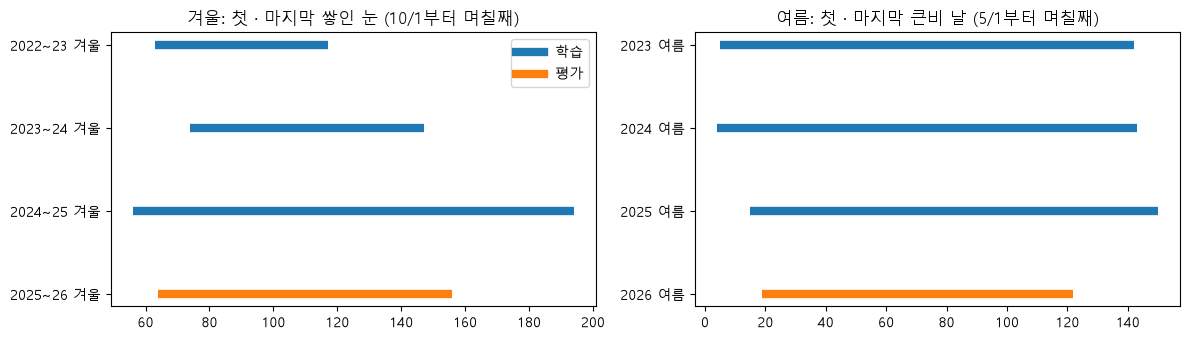

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, k, title in ((axes[0], 'W', '겨울: 첫 · 마지막 쌓인 눈 (10/1부터 며칠째)'), (axes[1], 'S', '여름: 첫 · 마지막 큰비 날 (5/1부터 며칠째)')):
    t = fl[fl['season'].str.startswith(k)]
    for i, r in enumerate(t.itertuples()):
        c = 'tab:blue' if r.split == 'train' else 'tab:orange'
        ax.plot([r.first_offset, r.last_offset], [i, i], color=c, lw=6, solid_capstyle='butt')
    ax.set_yticks(range(len(t)), t['name'])
    ax.set_title(title)
    ax.invert_yaxis()
axes[0].plot([], [], color='tab:blue', lw=6, label='학습')
axes[0].plot([], [], color='tab:orange', lw=6, label='평가')
axes[0].legend()
plt.tight_layout()
plt.savefig(ROOT / 'outputs/figures/season_first_last.png', dpi=150)

## 4. 연구 기간 후보

학습 3년의 첫 · 마지막 날로 후보를 만든다. `train_coverage` 는 학습 기간 악천후 날(겨울: 쌓인 눈 사건, 여름: 큰비 날) 중 그 기간 안에 들어오는 비율이다.

**추천 규칙**: 학습 coverage 90% 이상인 후보 중 가장 짧은 것. 평가 시즌은 기간을 정할 때 쓰지 않고, 들어오는지만 확인한다.

In [6]:
opts = W.period_options(hourly, ev, fl)
rec = W.recommend_period(opts, min_coverage=0.9)
display(opts.style.format({'train_coverage': '{:.0%}', 'eval_coverage': '{:.0%}'}))
rec

,season_kind,option,start,end,days,train_coverage,eval_coverage
0,겨울,평균,12-04,03-03,89,86%,71%
1,겨울,평균 ± 1주,11-27,03-10,103,92%,100%
2,겨울,평균 ± 2주,11-20,03-17,117,95%,100%
3,겨울,가장 이른 ~ 가장 늦은,11-26,04-13,139,100%,100%
4,여름,평균,05-09,09-23,138,92%,100%
5,여름,평균 ± 1주,05-02,09-30,152,100%,100%
6,여름,평균 ± 2주,04-25,10-07,166,100%,100%
7,여름,가장 이른 ~ 가장 늦은,05-05,09-28,147,100%,100%


{'겨울': {'option': '평균 ± 1주',
  'start': '11-27',
  'end': '03-10',
  'train_coverage': 0.919,
  'eval_coverage': 1.0},
 '여름': {'option': '평균',
  'start': '05-09',
  'end': '09-23',
  'train_coverage': 0.917,
  'eval_coverage': 1.0}}

## 5. 악천후일 · 비교일 (C 교통량 수집용)

교통량 API는 한 번에 1지점 × 1시간만 주므로 날짜 수를 제한한다 (학습 30일 · 평가 15일, 2025-12-04는 항상 포함).

In [7]:
days, hourly = W.select_days(hourly, ev, rec, max_train=30, max_eval=15)
print(days.groupby(['split', 'role']).size())
days.head(20)

split  role
eval   비교일     15
       악천후일    15
train  비교일     30
       악천후일    30
dtype: int64


,date,role,season,split,intensity,precip_mm,new_snow_cm,matched_date,weekday,season_name
0,2025-11-28,비교일,W2025,eval,,0.0,0.0,2025-12-05,Friday,2025~26 겨울
1,2025-12-04,악천후일,W2025,eval,많은 눈,4.0,5.1,2025-12-18,Thursday,2025~26 겨울
2,2025-12-05,악천후일,W2025,eval,많은 눈,0.0,0.0,2025-11-28,Friday,2025~26 겨울
3,2025-12-18,비교일,W2025,eval,,0.0,0.0,2025-12-04,Thursday,2025~26 겨울
4,2026-01-05,비교일,W2025,eval,,0.0,0.0,2026-01-12,Monday,2025~26 겨울
5,2026-01-06,비교일,W2025,eval,,0.0,0.0,2026-01-13,Tuesday,2025~26 겨울
6,2026-01-12,악천후일,W2025,eval,보통 눈,1.2,1.6,2026-01-05,Monday,2025~26 겨울
7,2026-01-13,악천후일,W2025,eval,보통 눈,1.5,1.2,2026-01-06,Tuesday,2025~26 겨울
8,2026-01-16,비교일,W2025,eval,,0.0,0.0,2026-01-23,Friday,2025~26 겨울
9,2026-01-19,악천후일,W2025,eval,보통 눈,1.0,1.3,2026-01-26,Monday,2025~26 겨울


## 6. 서울 기상특보 상태 (crawling/kma_warning.py 결과)

시간마다 `warn_snow · warn_rain · warn_cold` (0 없음 · 1 주의보 · 2 경보), 발효 권역 수, **발표됐지만 아직 발효 전(upcoming)**, 발효 후 지난 시간을 붙인다. 그 시각까지 발효된 것만 반영해 미래 정보가 섞이지 않는다.

In [8]:
hourly, w_items, w_eps = W.add_warnings(hourly)
if w_eps is not None:
    display(w_eps.groupby(['split', 'kind']).size().unstack(fill_value=0))
    display(hourly.loc[(hourly['datetime'] >= '2025-12-04 14:00') & (hourly['datetime'] <= '2025-12-05 10:00'),
                       ['datetime', 'precip_type', 'warn_snow', 'warn_snow_areas', 'warn_snow_upcoming', 'warn_snow_hours']])

kind,cold,rain,snow
split,,,
eval,9,6,3
train,15,39,17


,datetime,precip_type,warn_snow,warn_snow_areas,warn_snow_upcoming,warn_snow_hours
27854,2025-12-04 14:00:00,,0,0,0,NaN
27855,2025-12-04 15:00:00,,0,0,0,NaN
27856,2025-12-04 16:00:00,,0,0,0,NaN
27857,2025-12-04 17:00:00,,0,0,1,NaN
27858,2025-12-04 18:00:00,snow,1,4,0,0.0
27859,2025-12-04 19:00:00,snow,1,4,0,1.0
27860,2025-12-04 20:00:00,snow,0,0,0,NaN
27861,2025-12-04 21:00:00,snow,0,0,0,NaN
27862,2025-12-04 22:00:00,,0,0,0,NaN
27863,2025-12-04 23:00:00,,0,0,0,NaN


## 7. 저장 (`RUN_BUILD = True`일 때만 · train_dev / holdout)

In [9]:
if not RUN_BUILD:
    print('건너뜀: RUN_BUILD = False (data/shared · outputs/tables · config/periods.yaml 저장 없음)')
else:
    (ROOT / 'outputs/figures').mkdir(parents=True, exist_ok=True)
    W.save_outputs(hourly, ev, fl, opts, rec, days, warn_items=w_items, warn_eps=w_eps)
print((ROOT / 'config/periods.yaml').read_text(encoding='utf-8')[:800])

건너뜀: RUN_BUILD = False (data/shared · outputs/tables · config/periods.yaml 저장 없음)
updated: 2026-11-22 KST
owner: team
station: ASOS 서울(108)
timezone: Asia/Seoul

seasons:
  train:
    - 2022~23 겨울
    - 2023~24 겨울
    - 2024~25 겨울
    - 2023 여름
    - 2024 여름
    - 2025 여름
  eval:
    - 2025~26 겨울
    - 2026 여름

research_period:
  겨울: {option: 평균 ± 1주, start: 11-27, end: 03-10, train_coverage: 0.919, eval_coverage: 1.0}
  여름: {option: 평균, start: 05-09, end: 09-23, train_coverage: 0.917, eval_coverage: 1.0}

periods:
  - {season: 2022-23_winter, split: train, start: 2022-11-27, end: 2023-03-10, baseline_start: 2022-10-30}
  - {season: 2023_summer, split: train, start: 2023-05-09, end: 2023-09-23, baseline_start: 2023-04-11}
  - {season: 2023-24_winter, split: train, start: 2023-11-27, end: 2024-03-10, baseline_start: 2023-10-30}
  - {season: 2024_summer, split: train, sta
